1. Config
Here I am defining the size of the bounding box, fields to retrive, query details, and the temporary local output location of the download. The query uses the project's Tessera bounding box and retrieves parcel polygons intersecting that area.

In [7]:
from pathlib import Path 
import requests
import geopandas as gpd
import pandas as pd
import time

#URL for the service allowing the download of the dataset
SERVICE_URL = (
    "https://gis.colorado.gov/public/rest/services/"
    "Address_and_Parcel/Colorado_Public_Parcels/FeatureServer/0"
)

QUERY_URL = f"{SERVICE_URL}/query"

#project bounding box xmin, ymin, xmax, ymax
BBOX = (-105.5, 40.5, -104.8, 40.9)

OUT_FIELDS = ",".join([
    "OBJECTID",
    "countyName",
    "countyFips",
    "parcel_id",
    "landSqft",
    "landAcres",
    "landUseDsc",
    "landUseCde",
    "zoningCode",
    "zoningDesc",
    "dateReceived"
])

# Create temp data directory
OUTPUT_DIR = Path("data")
OUTPUT_DIR.mkdir(exist_ok=True)

OUTPUT_FILE = OUTPUT_DIR / "colorado_parcels_raw.gpkg"

print("Query URL:", QUERY_URL)
print("Bounding box:", BBOX)
print("Output file:", OUTPUT_FILE)

Query URL: https://gis.colorado.gov/public/rest/services/Address_and_Parcel/Colorado_Public_Parcels/FeatureServer/0/query
Bounding box: (-105.5, 40.5, -104.8, 40.9)
Output file: data/colorado_parcels_raw.gpkg


2. Download parcel IDS 
Sends a query to the Colorado Public Parcels service using the project's bounding box requesting the Object IDs. This way I can verify that all 99146 parcels get grabbed and can later download dataset in batches to avoid any silent truncations

In [8]:
spatial_params = {
    "where": "1=1",
    "geometry": ",".join(map(str, BBOX)),
    "geometryType": "esriGeometryEnvelope",
    "inSR": 4326,
    "spatialRel": "esriSpatialRelIntersects",
    "returnIdsOnly": "true",
    "f": "json"
}

response = requests.get(
    QUERY_URL,
    params=spatial_params,
    timeout=120
)

response.raise_for_status()
result = response.json()

if "error" in result:
    raise RuntimeError(result["error"])

object_ids = result.get("objectIds", [])

print(f"Matching parcels: {len(object_ids):,}")

if not object_ids:
    raise RuntimeError("No parcel IDs returned. Check the query.")


Matching parcels: 99,146


3. Download parcel features
Here I actually download the geometry and selected attribute fieds for all 99,146 matched parcels. I am downloading in batches of 500 to avoid exceeding the ArcGIS FeatureServer response limit. Each batch gets appended to a GeoPackage containing the complete raw parcel dataset

In [9]:

BATCH_SIZE = 500

# Remove an older download so we start fresh
if OUTPUT_FILE.exists():
    OUTPUT_FILE.unlink()

total_downloaded = 0

for start in range(0, len(object_ids), BATCH_SIZE):

    batch_ids = object_ids[start:start + BATCH_SIZE]

    params = {
        "objectIds": ",".join(map(str, batch_ids)),
        "outFields": OUT_FIELDS,
        "returnGeometry": "true",
        "outSR": 4326,
        "f": "geojson"
    }

    # Use POST instead of GET
    response = requests.post(
        QUERY_URL,
        data=params,
        timeout=180
    )

    if not response.ok:
        print(f"Failed batch starting at {start}")
        print("HTTP status:", response.status_code)
        print("Response:", response.text[:1000])
        response.raise_for_status()

    geojson = response.json()

    if "error" in geojson:
        raise RuntimeError(geojson["error"])

    features = geojson.get("features", [])

    if not features:
        print(f"Empty batch starting at {start}")
        continue

    batch_gdf = gpd.GeoDataFrame.from_features(
        features,
        crs="EPSG:4326"
    )

    mode = "w" if total_downloaded == 0 else "a"

    batch_gdf.to_file(
        OUTPUT_FILE,
        layer="parcels",
        driver="GPKG",
        mode=mode,
        index=False
    )

    total_downloaded += len(batch_gdf)

    print(
        f"Downloaded {total_downloaded:,} "
        f"/ {len(object_ids):,} parcels"
    )

    time.sleep(0.2)

print("\nDownload finished.")
print(f"Total downloaded: {total_downloaded:,}")
print(f"Saved to: {OUTPUT_FILE}")


Downloaded 500 / 99,146 parcels


/s/bach/j/under/C835397396/csFall26/cs435/co-fire/.venv/lib/python3.13/site-packages/pyogrio/raw.py:733: RuntimeWarning: A geometry of type MULTIPOLYGON is inserted into layer parcels of geometry type POLYGON, which is not normally allowed by the GeoPackage specification, but the driver will however do it. To create a conformant GeoPackage, if using ogr2ogr, the -nlt option can be used to override the layer geometry type. This warning will no longer be emitted for this combination of layer and feature geometry type.
  ogr_write(


Downloaded 1,000 / 99,146 parcels


/s/bach/j/under/C835397396/csFall26/cs435/co-fire/.venv/lib/python3.13/site-packages/pyogrio/raw.py:733: RuntimeWarning: A geometry of type MULTIPOLYGON is inserted into layer parcels of geometry type POLYGON, which is not normally allowed by the GeoPackage specification, but the driver will however do it. To create a conformant GeoPackage, if using ogr2ogr, the -nlt option can be used to override the layer geometry type. This warning will no longer be emitted for this combination of layer and feature geometry type.
  ogr_write(


Downloaded 1,500 / 99,146 parcels
Downloaded 2,000 / 99,146 parcels
Downloaded 2,500 / 99,146 parcels


/s/bach/j/under/C835397396/csFall26/cs435/co-fire/.venv/lib/python3.13/site-packages/pyogrio/raw.py:733: RuntimeWarning: A geometry of type MULTIPOLYGON is inserted into layer parcels of geometry type POLYGON, which is not normally allowed by the GeoPackage specification, but the driver will however do it. To create a conformant GeoPackage, if using ogr2ogr, the -nlt option can be used to override the layer geometry type. This warning will no longer be emitted for this combination of layer and feature geometry type.
  ogr_write(


... (171 outputs left out)

/s/bach/j/under/C835397396/csFall26/cs435/co-fire/.venv/lib/python3.13/site-packages/pyogrio/raw.py:733: RuntimeWarning: A geometry of type MULTIPOLYGON is inserted into layer parcels of geometry type POLYGON, which is not normally allowed by the GeoPackage specification, but the driver will however do it. To create a conformant GeoPackage, if using ogr2ogr, the -nlt option can be used to override the layer geometry type. This warning will no longer be emitted for this combination of layer and feature geometry type.
  ogr_write(


Downloaded 98,000 / 99,146 parcels
Downloaded 98,500 / 99,146 parcels


/s/bach/j/under/C835397396/csFall26/cs435/co-fire/.venv/lib/python3.13/site-packages/pyogrio/raw.py:733: RuntimeWarning: A geometry of type MULTIPOLYGON is inserted into layer parcels of geometry type POLYGON, which is not normally allowed by the GeoPackage specification, but the driver will however do it. To create a conformant GeoPackage, if using ogr2ogr, the -nlt option can be used to override the layer geometry type. This warning will no longer be emitted for this combination of layer and feature geometry type.
  ogr_write(


Downloaded 99,000 / 99,146 parcels
Downloaded 99,146 / 99,146 parcels

Download finished.
Total downloaded: 99,146
Saved to: data/colorado_parcels_raw.gpkg


4. Verify the downloaded geopackage
Here I am checking that all the parcels were downloaded and appended correctly 

Downloaded parcels: 99,146
Expected parcels:   99,146
CRS: EPSG:4326
Geometry types:
Polygon         54146
MultiPolygon    45000
Name: count, dtype: int64

Columns:
['OBJECTID', 'countyName', 'countyFips', 'parcel_id', 'landSqft', 'landAcres', 'landUseDsc', 'landUseCde', 'zoningCode', 'zoningDesc', 'dateReceived', 'geometry']

Land-use descriptions:
landUseDsc
Residential        77211
Agricultural        5565
Commercial          3797
Mobile Home         3712
Exempt              3612
Non Taxable         2183
Multiple Unit       1542
None                 899
Vacant Land          344
Industrial           117
Partial Exempt        78
MH Park               45
Nat Resources         22
Real State Assd       13
Natural Rsrc           6
Name: count, dtype: int64
Missing geometries: 0
Empty geometries: 0
Invalid geometries: 38

Missing values by column:
zoningCode      99146
zoningDesc      99146
landUseCde      99146
landSqft        99146
landAcres       90511
landUseDsc        899
countyName  

<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

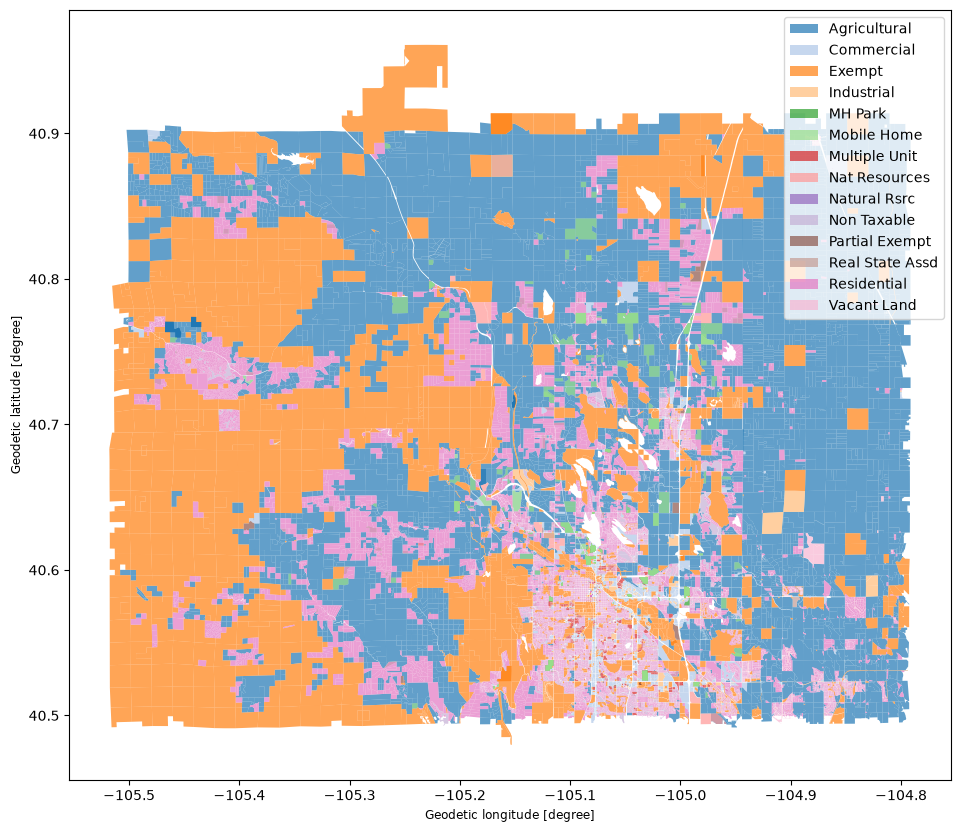

In [10]:
parcels = gpd.read_file(OUTPUT_FILE, layer="parcels")

print(f"Downloaded parcels: {len(parcels):,}")
print(f"Expected parcels:   {len(object_ids):,}")
print(f"CRS: {parcels.crs}")
print(f"Geometry types:\n{parcels.geom_type.value_counts()}")

print("\nColumns:")
print(parcels.columns.tolist())

print("\nLand-use descriptions:")
print(parcels["landUseDsc"].value_counts(dropna=False))

print("Missing geometries:", parcels.geometry.isna().sum())
print("Empty geometries:", parcels.geometry.is_empty.sum())
print("Invalid geometries:", (~parcels.geometry.is_valid).sum())

print("\nMissing values by column:")
print(parcels.isna().sum().sort_values(ascending=False))

parcels.plot(
    column="landUseDsc",
    legend=True,
    figsize=(12, 10),
    linewidth=0,
    alpha=0.7
)

This is about what I expected. After testing the outputs of the query seperately in browser, many of the fields were not populated. The landUseDsc is the primary populated field of interest (and either OBJECTID or parcel_id as general ids to keep track of). 899 parcels have null values for landUseDsc, which is ~0.9% of the total dataset. I don't believe this is large enough to have a noticeable effect on training the model, though it is something we should take note of when reporting on the final model and it's predictions. From here we will leave this version of the dataset untouched and build fresh geopackages or geotiffs from this original so we have a 'source of truth' if we need to trace a processed record back to the original. There were also 38 'invalid geometries' which I checked below. this is also only ~.038% of the dataset so also shouldn't be a significant obstacle, but I repair them below as well so we can safely rasterize with exclusively valid polygons. There were three main reasons for geometries to be marked invalid: too few points to form a valid polygon, a hole lying outside its polygon shell, and a ring self-intersection where a polygon boundary crosses itself. If that recorded hole lies outside the boundary of the polygon it should be inside that makes it invalid, and ring self intersection (polygons overlapping eachother).

5. Repair invalid geometries and normalize categories
Here I am trying to fix the invalid geometries and create a geo file with valid polygons to rasterize without error. There are also a number of categories in landUseDsc that are synonyms with each other (MH Park and mobile home park, nat resources and natural rscs), so these will be converged into single categories.

In [11]:
# Inspect exact land-use values, including capitalization and whitespace
print("Original land-use values:")
for value in sorted(parcels["landUseDsc"].dropna().unique()):
    print(repr(value))

# Inspect invalid geometry examples
invalid = parcels.loc[~parcels.geometry.is_valid].copy()

print("\nInvalid geometry count:", len(invalid))
print("\nGeometry validity reasons:")
print(invalid.geometry.is_valid_reason().value_counts())

Original land-use values:
'Agricultural'
'Commercial'
'Exempt'
'Industrial'
'MH Park'
'Mobile Home'
'Multiple Unit'
'Nat Resources'
'Natural Rsrc'
'Non Taxable'
'Partial Exempt'
'Real State Assd'
'Residential'
'Vacant Land'

Invalid geometry count: 38

Geometry validity reasons:
Too few points in geometry component[-105.042567269 40.594254016]        1
Too few points in geometry component[-105.097621558 40.552855112]        1
Too few points in geometry component[-105.11650943 40.5521184150001]     1
Too few points in geometry component[-105.042106054 40.59288817]         1
Ring Self-intersection[-105.040702445 40.607377559]                      1
Hole lies outside shell[-105.060161492 40.5284012720001]                 1
Too few points in geometry component[-105.115978586 40.54370385]         1
Ring Self-intersection[-105.256528169 40.662092279]                      1
Hole lies outside shell[-105.132370036 40.6093348300001]                 1
Too few points in geometry component[-105.095

In [12]:
from shapely.geometry import Polygon, MultiPolygon, GeometryCollection
from shapely.ops import unary_union
from shapely.validation import make_valid

def extract_polygons(geom):
    """Recursively extract polygon components from a geometry."""
    if geom is None or geom.is_empty:
        return []

    if isinstance(geom, Polygon):
        return [geom]

    if isinstance(geom, (MultiPolygon, GeometryCollection)):
        polygons = []
        for part in geom.geoms:
            polygons.extend(extract_polygons(part))
        return polygons

    return []


def repair_polygon(geom):
    """Repair invalid geometry and retain polygonal components."""
    if geom is None or geom.is_empty:
        return None

    repaired = geom if geom.is_valid else make_valid(geom)
    polygons = extract_polygons(repaired)

    if not polygons:
        return None

    return unary_union(polygons)

clean_parcels = parcels.copy()

# Preserve the source category
clean_parcels["landUseDsc_original"] = clean_parcels["landUseDsc"]

# Repair all geometries
clean_parcels["geometry"] = clean_parcels.geometry.apply(repair_polygon)

print("Invalid geometries remaining:",
      (~clean_parcels.geometry.is_valid).sum())

print("Missing geometries after repair:",
      clean_parcels.geometry.isna().sum())

print("Empty geometries after repair:",
      clean_parcels.geometry.is_empty.sum())

print("\nGeometry types after repair:")
print(clean_parcels.geom_type.value_counts())

Invalid geometries remaining: 0
Missing geometries after repair: 0
Empty geometries after repair: 0

Geometry types after repair:
Polygon         99016
MultiPolygon      130
Name: count, dtype: int64


Note here the geometry types changed substantially. There are now 99016 polygons and 130 multipolygons, as opposed to the original 52646 polygons and 46500 multipolygons. This is not necessarily a problem though as the repair on the invalid polygons also returned simpler polygons when the geometries allowed for it, though we still have the original dataset if we need to compare them later.

In [13]:
land_use_mapping = {
    "Nat Resources": "Natural Resources",
    "Natural Rsrc": "Natural Resources",
    "MH Park": "Mobile Home Park",
    "Mobile Home": "Mobile Home Park",
}

clean_parcels["landUseDsc_normalized"] = (
    clean_parcels["landUseDsc"]
    .str.strip()
    .replace(land_use_mapping)
    .fillna("Unknown")
)

print(clean_parcels["landUseDsc_normalized"].value_counts(dropna=False))

CLEAN_OUTPUT_FILE = OUTPUT_DIR / "colorado_parcels_cleaned.gpkg"

clean_parcels.to_file(
    CLEAN_OUTPUT_FILE,
    layer="parcels",
    driver="GPKG",
    index=False
)

print(f"Saved: {CLEAN_OUTPUT_FILE}")

landUseDsc_normalized
Residential          77211
Agricultural          5565
Commercial            3797
Mobile Home Park      3757
Exempt                3612
Non Taxable           2183
Multiple Unit         1542
Unknown                899
Vacant Land            344
Industrial             117
Partial Exempt          78
Natural Resources       28
Real State Assd         13
Name: count, dtype: int64
Saved: data/colorado_parcels_cleaned.gpkg


A few things to note here. I made a new category "Unknown" for the 899 parcels lacking a land use description so they don't get dropped completely from the datasest. The mobile home categories and natural resources categories were combined correctly as well. I left Exempt, Non Taxable, and Partial Exempt seperate as they are slightly vague and this gives us the flexibility to combine them if necessary later.

6. Reproject the parcels
Right now the parcel data uses EPSG:4326 coordinate system, so we need to reproject it in EPSG:32613 (UTM Zone 13N) to match Ian's tessera raster.

In [14]:
# Reproject cleaned parcels to Tessera's CRS
parcels_projected = clean_parcels.to_crs("EPSG:32613")

print("Original CRS:", clean_parcels.crs)
print("Projected CRS:", parcels_projected.crs)

print("\nProjected bounds:")
print(parcels_projected.total_bounds)

print("\nFeature count:", len(parcels_projected))

Original CRS: EPSG:4326
Projected CRS: EPSG:32613

Projected bounds:
[ 456170.30887609 4481025.27853263  517623.54570398 4534442.202313  ]

Feature count: 99146


7. Check Projection
The bounding-box comparison confirms that the overall spatial extent of the parcel dataset contains the Tessera raster extent. This does not guarantee complete parcel coverage within the raster, since the parcel geometries themselves may leave gaps. Coverage is evaluated more directly after rasterization by counting pixels without an assigned parcel.

In [18]:
from affine import Affine
from shapely.geometry import box
import geopandas as gpd

TESSERA_TRANSFORM = Affine(
    10, 0, 457630,
    0, -10, 4527780
)

TESSERA_WIDTH = 5932
TESSERA_HEIGHT = 4453
TESSERA_CRS = "EPSG:32613"

# Construct Tessera's exact spatial extent
tessera_bounds = box(
    457630,
    4483250,
    516950,
    4527780
)

# Calculate parcel coverage
# This just confirms whether or not the data set fully covers the tessera embed
parcel_bounds = box(*parcels_projected.total_bounds)

print("Tessera bounds:")
print(tessera_bounds.bounds)

print("\nParcel bounds:")
print(parcel_bounds.bounds)

print("\nParcel coverage intersects Tessera:",
      parcel_bounds.intersects(tessera_bounds))

print("\nParcel coverage contains Tessera:",
      parcel_bounds.contains(tessera_bounds))

print("\nTessera coverage contains parcel bounds:",
      tessera_bounds.contains(parcel_bounds))

# Reconstruct the exact Tessera extent
tessera_bounds = box(
    457630,
    4483250,
    516950,
    4527780
)

# Clip parcels to the Tessera extent
tessera_parcels = gpd.clip(
    parcels_projected,
    tessera_bounds
).reset_index(drop=True)

# Validate the clipped result
print(f"Original parcels: {len(parcels_projected):,}")
print(f"Clipped parcels: {len(tessera_parcels):,}")
print(f"CRS: {tessera_parcels.crs}")
print(f"Invalid geometries: {(~tessera_parcels.geometry.is_valid).sum()}")
print(f"Empty geometries: {tessera_parcels.geometry.is_empty.sum()}")
print(f"Missing geometries: {tessera_parcels.geometry.isna().sum()}")

print("\nNormalized land-use categories:")
print(tessera_parcels["landUseDsc_normalized"].value_counts(dropna=False))



Tessera bounds:
(457630.0, 4483250.0, 516950.0, 4527780.0)

Parcel bounds:
(456170.30887609173, 4481025.278532628, 517623.5457039842, 4534442.202313005)

Parcel coverage intersects Tessera: True

Parcel coverage contains Tessera: True

Tessera coverage contains parcel bounds: False
Original parcels: 99,146
Clipped parcels: 99,146
CRS: EPSG:32613
Invalid geometries: 0
Empty geometries: 0
Missing geometries: 0

Normalized land-use categories:
landUseDsc_normalized
Residential          77211
Agricultural          5565
Commercial            3797
Mobile Home Park      3757
Exempt                3612
Non Taxable           2183
Multiple Unit         1542
Unknown                899
Vacant Land            344
Industrial             117
Partial Exempt          78
Natural Resources       28
Real State Assd         13
Name: count, dtype: int64


8. Raster
Its at this point I build the raster with the following category codes:
0   No parcel assigned (NoData)
1   Residential
2   Agricultural
3   Commercial
4   Mobile Home Park
5   Exempt
6   Non Taxable
7   Multiple Unit
8   Unknown
9   Vacant Land
10  Industrial
11  Partial Exempt
12  Natural Resources
13  Real State Assd
254 Multiple categories at pixel center

I am building this first raster to pixel centers because multiple categories can be inside one pixel, so whichever parcel category claims the pixel's center takes the pixel. This is also why I included the (arbitrary) 254 code in the case of more than one parcel category bein at the pixel's center. This is flag for ambiguity in the pixel assignment and not a legitimate land-use class.

In [19]:

import numpy as np
import pandas as pd
import rasterio
from rasterio.features import rasterize
from pathlib import Path

# Stable category-to-code mapping
land_use_codes = {
    "Residential": 1,
    "Agricultural": 2,
    "Commercial": 3,
    "Mobile Home Park": 4,
    "Exempt": 5,
    "Non Taxable": 6,
    "Multiple Unit": 7,
    "Unknown": 8,
    "Vacant Land": 9,
    "Industrial": 10,
    "Partial Exempt": 11,
    "Natural Resources": 12,
    "Real State Assd": 13
}

NO_PARCEL = 0
AMBIGUOUS = 254

# Prepare output arrays
out_shape = (TESSERA_HEIGHT, TESSERA_WIDTH)

land_use_raster = np.zeros(out_shape, dtype=np.uint8)
category_hits = np.zeros(out_shape, dtype=np.uint8)

# Rasterize each category separately.
# This lets us identify pixels claimed by multiple categories.
for category, code in land_use_codes.items():

    category_geometries = tessera_parcels.loc[
        tessera_parcels["landUseDsc_normalized"] == category,
        "geometry"
    ]

    shapes = (
        (geom, 1)
        for geom in category_geometries
        if geom is not None and not geom.is_empty
    )

    category_mask = rasterize(
        shapes=shapes,
        out_shape=out_shape,
        transform=TESSERA_TRANSFORM,
        fill=0,
        dtype="uint8",
        all_touched=False
    )

    covered = category_mask == 1

    # Assign the category only where no other category
    # has already claimed the pixel center.
    first_category = covered & (category_hits == 0)
    land_use_raster[first_category] = code

    category_hits[covered] += 1

# Flag pixels claimed by multiple distinct categories
ambiguous_pixels = category_hits > 1
land_use_raster[ambiguous_pixels] = AMBIGUOUS

# Save output directory and files
OUTPUT_DIR = Path("data")
OUTPUT_DIR.mkdir(exist_ok=True)

RASTER_FILE = OUTPUT_DIR / "land_use_aligned.tif"
MAPPING_FILE = OUTPUT_DIR / "land_use_class_mapping.csv"

# Write the raster using the exact Tessera grid
profile = {
    "driver": "GTiff",
    "height": TESSERA_HEIGHT,
    "width": TESSERA_WIDTH,
    "count": 1,
    "dtype": "uint8",
    "crs": TESSERA_CRS,
    "transform": TESSERA_TRANSFORM,
    "nodata": NO_PARCEL,
    "compress": "lzw"
}

with rasterio.open(RASTER_FILE, "w", **profile) as dst:
    dst.write(land_use_raster, 1)
    dst.set_band_description(1, "Parcel land-use category")

# Save the code mapping
mapping_rows = [
    {"code": 0, "category": "No parcel assigned", "meaning": "No parcel covers pixel center"},
    *[
        {"code": code, "category": category, "meaning": "Normalized parcel land use"}
        for category, code in land_use_codes.items()
    ],
    {"code": 254, "category": "Ambiguous", "meaning": "Multiple land-use categories cover pixel center"}
]

pd.DataFrame(mapping_rows).to_csv(MAPPING_FILE, index=False)

print("Rasterization complete.")
print(f"Raster: {RASTER_FILE}")
print(f"Mapping: {MAPPING_FILE}")
print(f"Raster dimensions: {TESSERA_WIDTH} x {TESSERA_HEIGHT}")
print(f"Total pixels: {land_use_raster.size:,}")
print(f"Pixels with parcel assignments: {(land_use_raster != NO_PARCEL).sum():,}")
print(f"Pixels with no parcel: {(land_use_raster == NO_PARCEL).sum():,}")
print(f"Ambiguous pixels: {ambiguous_pixels.sum():,}")


Rasterization complete.
Raster: data/land_use_aligned.tif
Mapping: data/land_use_class_mapping.csv
Raster dimensions: 5932 x 4453
Total pixels: 26,415,196
Pixels with parcel assignments: 25,689,288
Pixels with no parcel: 725,908
Ambiguous pixels: 388,719


In [21]:

from collections import Counter

with rasterio.open(RASTER_FILE) as src:
    print("Raster validation")
    print("-----------------")
    print(f"CRS: {src.crs}")
    print(f"Width: {src.width}")
    print(f"Height: {src.height}")
    print(f"Transform: {src.transform}")
    print(f"NoData: {src.nodata}")
    print(f"Band count: {src.count}")
    print(f"Data type: {src.dtypes[0]}")
    print(f"Bounds: {src.bounds}")

    raster_data = src.read(1)

print("\nCategory pixel counts:")
unique_codes, counts = np.unique(raster_data, return_counts=True)

for code, count in zip(unique_codes, counts):
    if code == 0:
        label = "No parcel assigned"
    elif code == 254:
        label = "Ambiguous"
    else:
        label = next(
            name for name, value in land_use_codes.items()
            if value == code
        )

    print(f"{code:3} | {label:25} | {count:>12,} pixels")

# Verify exact alignment
assert raster_data.shape == (TESSERA_HEIGHT, TESSERA_WIDTH)

with rasterio.open(RASTER_FILE) as src:
    assert src.crs.to_string() == TESSERA_CRS
    assert src.transform == TESSERA_TRANSFORM
    assert src.width == TESSERA_WIDTH
    assert src.height == TESSERA_HEIGHT

print("\nAll grid alignment checks passed.")


Raster validation
-----------------
CRS: EPSG:32613
Width: 5932
Height: 4453
Transform: | 10.00, 0.00, 457630.00|
| 0.00,-10.00, 4527780.00|
| 0.00, 0.00, 1.00|
NoData: 0.0
Band count: 1
Data type: uint8
Bounds: BoundingBox(left=457630.0, bottom=4483250.0, right=516950.0, top=4527780.0)

Category pixel counts:
  0 | No parcel assigned        |      725,908 pixels
  1 | Residential               |    3,362,251 pixels
  2 | Agricultural              |   12,516,144 pixels
  3 | Commercial                |      305,591 pixels
  4 | Mobile Home Park          |       21,335 pixels
  5 | Exempt                    |    8,612,130 pixels
  6 | Non Taxable               |      152,469 pixels
  7 | Multiple Unit             |       47,638 pixels
  8 | Unknown                   |       31,790 pixels
  9 | Vacant Land               |       45,637 pixels
 10 | Industrial                |      103,436 pixels
 11 | Partial Exempt            |       26,912 pixels
 12 | Natural Resources         |       

This result looks damning with 388,719 pixels being marked as ambiguous and 725,908 pixels with no parcel assigned, but the full tessera grid is 26.4 million pixels, so the counts come to ~1.47% ambiguous and ~2.75% with no parcel assignment. Neither of these are necessarily large enough to substantially affect model training and testing, though are still worth taking note of when it comes time to report. The abnormally large counts for Agriculture and Exempt also isn't inherently suspicious because pixel centers don't necessarily correspond to actual land area coverage.

The ambiguous pixels can come about when either two parcel polygons overlap or when parcel polygon boundaries meet at pixel centers. So to avoid arbitrarily assigning these pixels, I am checking which categories are claiming the ambiguous pixels. 

In [23]:
# Each category receives one bit in a uint16 value.
# A pixel's bitmask tells us exactly which categories claim it.

category_bitmask = np.zeros(
    (TESSERA_HEIGHT, TESSERA_WIDTH),
    dtype=np.uint16
)

for category, code in land_use_codes.items():

    category_geometries = tessera_parcels.loc[
        tessera_parcels["landUseDsc_normalized"] == category,
        "geometry"
    ]

    shapes = (
        (geom, 1)
        for geom in category_geometries
        if geom is not None and not geom.is_empty
    )

    category_mask = rasterize(
        shapes=shapes,
        out_shape=(TESSERA_HEIGHT, TESSERA_WIDTH),
        transform=TESSERA_TRANSFORM,
        fill=0,
        dtype="uint8",
        all_touched=False
    )

    # Set this category's bit wherever it claims a pixel
    category_bitmask[category_mask == 1] |= (1 << (code - 1))


# Count the distinct category combinations among ambiguous pixels
unique_masks, mask_counts = np.unique(
    category_bitmask[category_bitmask != 0],
    return_counts=True
)

category_names_by_code = {
    code: name for name, code in land_use_codes.items()
}

combinations = []

for mask, count in zip(unique_masks, mask_counts):

    categories = [
        category_names_by_code[code]
        for code in land_use_codes.values()
        if mask & (1 << (code - 1))
    ]

    if len(categories) > 1:
        combinations.append({
            "categories": " + ".join(categories),
            "number_of_pixels": int(count)
        })

ambiguity_df = pd.DataFrame(combinations)
ambiguity_df = ambiguity_df.sort_values(
    "number_of_pixels",
    ascending=False
)

print(ambiguity_df.to_string(index=False))

                                  categories  number_of_pixels
             Agricultural + Mobile Home Park            260328
              Residential + Mobile Home Park             60707
               Commercial + Mobile Home Park             34142
        Mobile Home Park + Natural Resources             30175
            Agricultural + Natural Resources               835
                        Residential + Exempt               832
                         Commercial + Exempt               342
                  Residential + Agricultural               312
               Mobile Home Park + Industrial               267
                    Residential + Commercial               187
        Commercial + Exempt + Partial Exempt               114
                       Agricultural + Exempt               114
                     Exempt + Partial Exempt                86
Agricultural + Commercial + Mobile Home Park                79
                  Commercial + Multiple Unit           

Here we can see that ~99% of the ambiguous pixels are made from the following combinations of parcel categories:
Agricultural + Mobile Home Park            260328
Residential + Mobile Home Park             60707
Commercial + Mobile Home Park             34142
Mobile Home Park + Natural Resources             30175
Each of these include Mobile Home Park, so with the next cell I'll investigate whether Mobile Home Park parcels are overlapping different parcels or just have a lot of boundary-only intersections (or a mixture of both). For the former, I'll further investigate which parcel categories should take priority, and for the latter we can (for the most part) safely leave them as ambiguous.

In [24]:
# Find actual geometric overlaps involving Mobile Home Park parcels.
# Areas are measured in square meters (EPSG:32613).

import numpy as np
import pandas as pd

gdf = tessera_parcels.reset_index(drop=True)

MH_CATEGORY = "Mobile Home Park"
spatial_index = gdf.sindex

mh_positions = np.flatnonzero(
    gdf["landUseDsc_normalized"].to_numpy() == MH_CATEGORY
)

overlap_records = []

for i in mh_positions:
    geom_i = gdf.geometry.iloc[i]

    # Find only parcels that spatially intersect this mobile home parcel
    candidates = spatial_index.query(
        geom_i,
        predicate="intersects"
    )

    for j in candidates:
        if i == j:
            continue

        category_j = gdf["landUseDsc_normalized"].iloc[j]

        # Only compare Mobile Home Park against other categories
        if category_j == MH_CATEGORY:
            continue

        geom_j = gdf.geometry.iloc[j]
        intersection_area = geom_i.intersection(geom_j).area

        overlap_records.append({
            "other_category": category_j,
            "intersection_area_m2": intersection_area
        })

overlaps_df = pd.DataFrame(overlap_records)

# Distinguish positive-area overlaps from boundary-only intersections
positive_overlaps = overlaps_df[
    overlaps_df["intersection_area_m2"] > 0.01
]

boundary_only = overlaps_df[
    overlaps_df["intersection_area_m2"] <= 0.01
]

print("Mobile Home Park intersection analysis")
print("--------------------------------------")
print(f"Total intersecting parcel pairs: {len(overlaps_df):,}")
print(f"Positive-area overlaps: {len(positive_overlaps):,}")
print(f"Boundary-only / negligible intersections: {len(boundary_only):,}")

print("\nPositive-area overlaps by other land-use category:")

if not positive_overlaps.empty:
    summary = positive_overlaps.groupby("other_category").agg(
        overlapping_pairs=("intersection_area_m2", "count"),
        total_overlap_m2=("intersection_area_m2", "sum"),
        largest_overlap_m2=("intersection_area_m2", "max")
    ).sort_values("total_overlap_m2", ascending=False)

    print(summary.to_string())
else:
    print("No significant positive-area overlaps found.")

Mobile Home Park intersection analysis
--------------------------------------
Total intersecting parcel pairs: 44,000
Positive-area overlaps: 445
Boundary-only / negligible intersections: 43,555

Positive-area overlaps by other land-use category:
                   overlapping_pairs  total_overlap_m2  largest_overlap_m2
other_category                                                            
Agricultural                     124      3.170443e+07        2.370146e+06
Residential                      254      6.734396e+06        2.839577e+05
Commercial                        37      4.645312e+06        9.558725e+05
Natural Resources                  3      3.317247e+06        2.715429e+06
Industrial                         1      2.659347e+04        2.659347e+04
Exempt                            26      2.936572e-01        2.624364e-02


Most intersecting Mobile Home Park parcel pairs had only boundary-level or negligible intersections. However, 445 pairs had positive-area overlaps, including some substantial intersections with Agricultural, Residential, Commercial, and Natural Resources parcels. These overlaps may explain some of the ambiguous raster pixels, but further investigation is needed to determine how much of the ambiguity is caused by genuine polygon overlap versus shared parcel boundaries. For now, ambiguous pixels are retained as a separate code rather than assigned arbitrarily.

The three outputs provide different ways to incorporate parcel land-use information into the group's analysis:
- land_use_aligned.tif: Complete categorical raster, preserving ambiguous and unassigned pixels.
- land_use_quality_mask.tif: Identifies confidently assigned, ambiguous, and unassigned pixels.
- land_use_model.tif: Contains only unambiguous land-use assignments, with ambiguous and unassigned pixels marked as NoData.
I recommend initially using land_use_model.tif as an additional predictor feature, while retaining the other two rasters for quality assessment and comparison. The group can later evaluate whether including ambiguous or unassigned areas differently changes model performance.

In [27]:
import rasterio
import numpy as np
from pathlib import Path

OUTPUT_DIR = Path("data")

# Load the original categorical raster
with rasterio.open(OUTPUT_DIR / "land_use_aligned.tif") as src:
    original = src.read(1)
    profile = src.profile.copy()

# --------------------------------------------------
# 1. Quality mask
# --------------------------------------------------
# 0 = Valid, unambiguous land-use category
# 1 = Ambiguous (254 in original raster)
# 2 = No parcel assigned (0 in original raster)

quality_mask = np.zeros(original.shape, dtype=np.uint8)

quality_mask[original == 254] = 1
quality_mask[original == 0] = 2

mask_profile = profile.copy()
mask_profile.update(
    dtype="uint8",
    nodata=None,
    count=1,
    compress="lzw"
)

with rasterio.open(
    OUTPUT_DIR / "land_use_quality_mask.tif",
    "w",
    **mask_profile
) as dst:
    dst.write(quality_mask, 1)
    dst.set_band_description(1, "Land-use data quality")

    dst.update_tags(
        CLASS_0="Valid unambiguous classification",
        CLASS_1="Ambiguous multiple land-use categories",
        CLASS_2="No parcel assigned"
    )

# --------------------------------------------------
# 2. Analysis-ready land-use raster
# --------------------------------------------------
# Preserve categories 1-13.
# Convert ambiguous and unassigned pixels to NoData (0).

model_raster = original.copy()
model_raster[(original == 254) | (original == 0)] = 0

model_profile = profile.copy()
model_profile.update(
    dtype="uint8",
    nodata=0,
    count=1,
    compress="lzw"
)

with rasterio.open(
    OUTPUT_DIR / "land_use_model.tif",
    "w",
    **model_profile
) as dst:
    dst.write(model_raster, 1)
    dst.set_band_description(1, "Unambiguous parcel land use")

    dst.update_tags(
        NODATA_MEANING="Ambiguous or no parcel assignment",
        CATEGORY_MAPPING="See land_use_class_mapping.csv"
    )

print("Additional TIFFs created successfully.")

print("\nQuality mask counts:")
values, counts = np.unique(quality_mask, return_counts=True)

for value, count in zip(values, counts):
    labels = {
        0: "Valid classification",
        1: "Ambiguous",
        2: "No parcel assigned"
    }
    print(f"{value}: {labels[value]} — {count:,}")

print("\nModel raster:")
print(f"Classified pixels: {np.count_nonzero(model_raster):,}")
print(f"NoData pixels: {np.count_nonzero(model_raster == 0):,}")

Additional TIFFs created successfully.

Quality mask counts:
0: Valid classification — 25,300,569
1: Ambiguous — 388,719
2: No parcel assigned — 725,908

Model raster:
Classified pixels: 25,300,569
NoData pixels: 1,114,627


In [28]:
for filename in [
    "land_use_aligned.tif",
    "land_use_quality_mask.tif",
    "land_use_model.tif"
]:
    path = OUTPUT_DIR / filename

    with rasterio.open(path) as src:
        print(f"\n{filename}")
        print(f"  Dimensions: {src.width} x {src.height}")
        print(f"  CRS: {src.crs}")
        print(f"  NoData: {src.nodata}")
        print(f"  Bands: {src.count}")
        print(f"  Transform matches: {src.transform == TESSERA_TRANSFORM}")

        assert src.width == TESSERA_WIDTH
        assert src.height == TESSERA_HEIGHT
        assert src.crs.to_string() == TESSERA_CRS
        assert src.transform == TESSERA_TRANSFORM

print("\nAll three rasters passed alignment checks.")


land_use_aligned.tif
  Dimensions: 5932 x 4453
  CRS: EPSG:32613
  NoData: 0.0
  Bands: 1
  Transform matches: True

land_use_quality_mask.tif
  Dimensions: 5932 x 4453
  CRS: EPSG:32613
  NoData: None
  Bands: 1
  Transform matches: True

land_use_model.tif
  Dimensions: 5932 x 4453
  CRS: EPSG:32613
  NoData: 0.0
  Bands: 1
  Transform matches: True

All three rasters passed alignment checks.


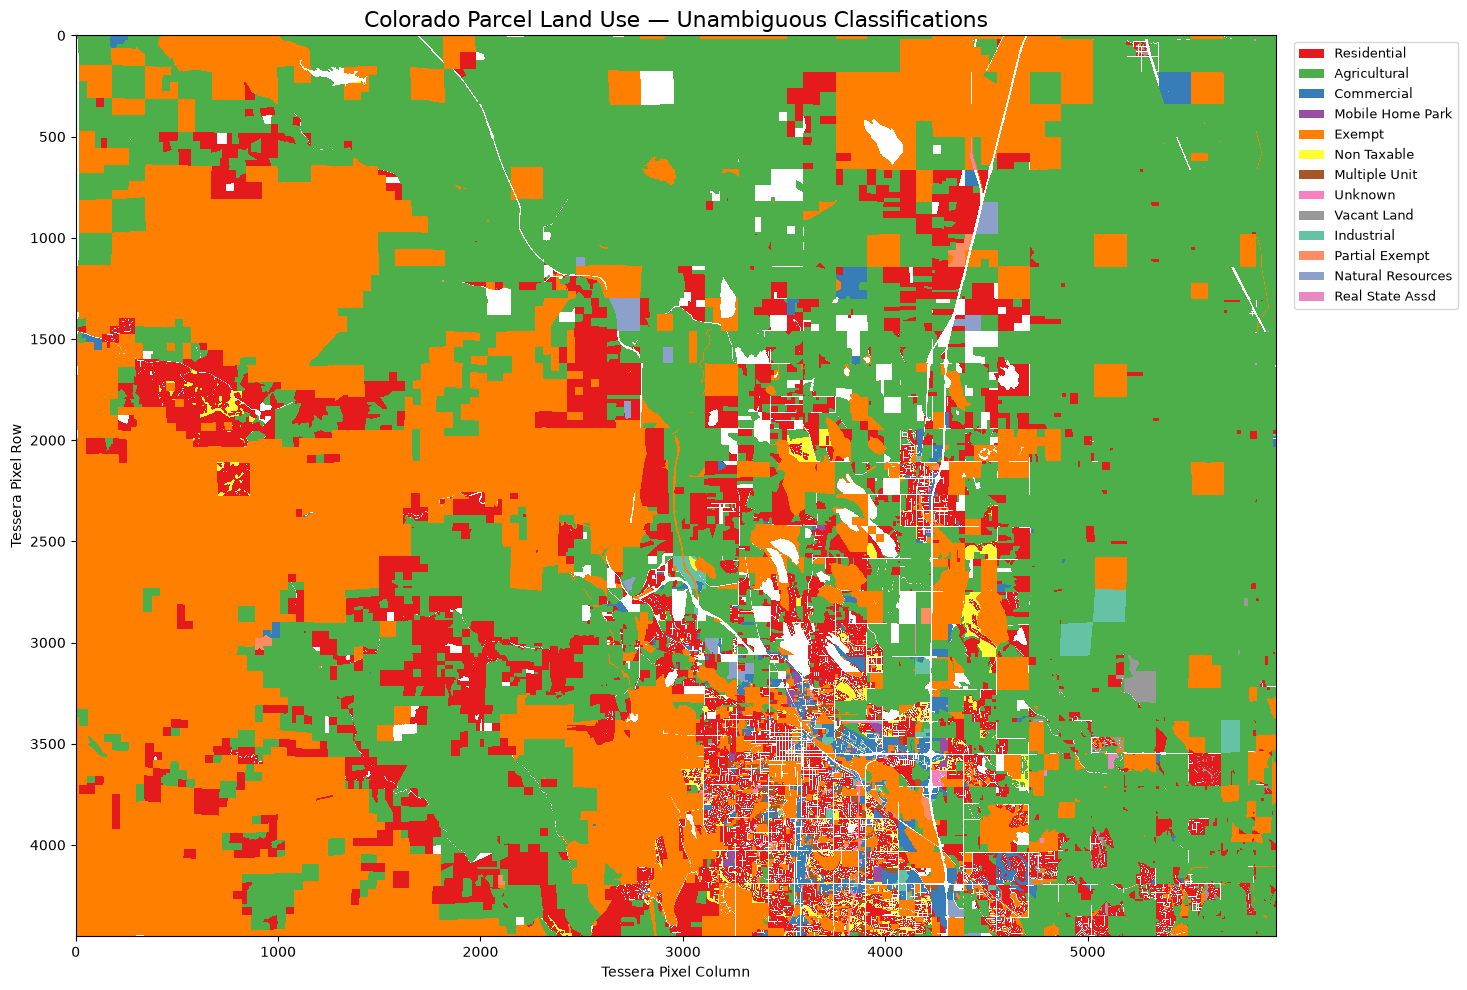

In [29]:

import rasterio
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch
from pathlib import Path

# Load analysis-ready raster
with rasterio.open("data/land_use_model.tif") as src:
    model_data = src.read(1)

# Category labels
category_labels = {
    1: "Residential",
    2: "Agricultural",
    3: "Commercial",
    4: "Mobile Home Park",
    5: "Exempt",
    6: "Non Taxable",
    7: "Multiple Unit",
    8: "Unknown",
    9: "Vacant Land",
    10: "Industrial",
    11: "Partial Exempt",
    12: "Natural Resources",
    13: "Real State Assd"
}

colors = [
    "#e41a1c",
    "#4daf4a",
    "#377eb8",
    "#984ea3",
    "#ff7f00",
    "#ffff33",
    "#a65628",
    "#f781bf",
    "#999999",
    "#66c2a5",
    "#fc8d62",
    "#8da0cb",
    "#e78ac3"
]

# Make NoData pixels transparent
masked_data = np.ma.masked_equal(model_data, 0)

cmap = ListedColormap(colors)
cmap.set_bad("white")

norm = BoundaryNorm(
    np.arange(0.5, 14.5, 1),
    cmap.N
)

# Plot
fig, ax = plt.subplots(figsize=(15, 10))

ax.imshow(
    masked_data,
    cmap=cmap,
    norm=norm,
    interpolation="nearest"
)

ax.set_title(
    "Colorado Parcel Land Use — Unambiguous Classifications",
    fontsize=16
)
ax.set_xlabel("Tessera Pixel Column")
ax.set_ylabel("Tessera Pixel Row")

legend_handles = [
    Patch(facecolor=colors[i], label=category_labels[code])
    for i, code in enumerate(category_labels)
]

ax.legend(
    handles=legend_handles,
    loc="upper left",
    bbox_to_anchor=(1.01, 1),
    fontsize=9
)

plt.tight_layout()

Path("data/visualizations").mkdir(parents=True, exist_ok=True)

plt.savefig(
    "data/visualizations/land_use_model_overview.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()


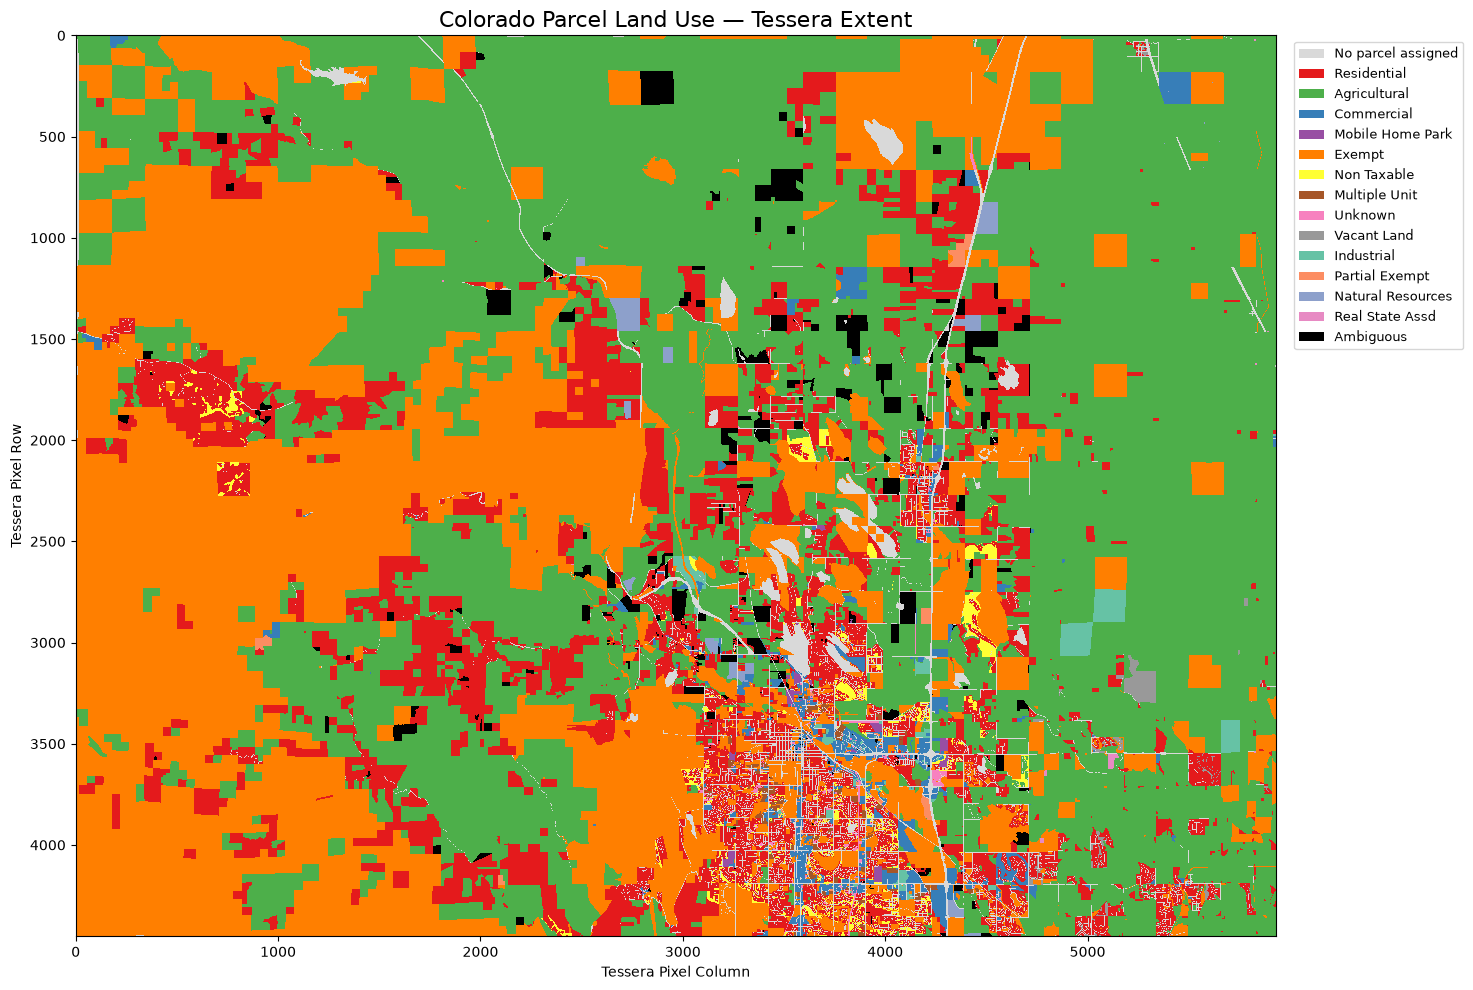

In [25]:

import rasterio
import numpy as np
import matplotlib.pyplot as plt

from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch
from pathlib import Path

# Read the land-use raster
with rasterio.open("data/land_use_aligned.tif") as src:
    land_use_data = src.read(1)
    raster_bounds = src.bounds

# Category names and codes
category_labels = {
    0: "No parcel assigned",
    1: "Residential",
    2: "Agricultural",
    3: "Commercial",
    4: "Mobile Home Park",
    5: "Exempt",
    6: "Non Taxable",
    7: "Multiple Unit",
    8: "Unknown",
    9: "Vacant Land",
    10: "Industrial",
    11: "Partial Exempt",
    12: "Natural Resources",
    13: "Real State Assd",
    254: "Ambiguous"
}

# Create a color for every raster code
colors = [
    "#d9d9d9",  # 0: No parcel
    "#e41a1c",  # 1: Residential
    "#4daf4a",  # 2: Agricultural
    "#377eb8",  # 3: Commercial
    "#984ea3",  # 4: Mobile Home Park
    "#ff7f00",  # 5: Exempt
    "#ffff33",  # 6: Non Taxable
    "#a65628",  # 7: Multiple Unit
    "#f781bf",  # 8: Unknown
    "#999999",  # 9: Vacant Land
    "#66c2a5",  # 10: Industrial
    "#fc8d62",  # 11: Partial Exempt
    "#8da0cb",  # 12: Natural Resources
    "#e78ac3",  # 13: Real State Assd
    "#000000"   # 254: Ambiguous
]

codes = list(category_labels.keys())

# Map actual raster values to consecutive display indices
display_data = np.zeros(land_use_data.shape, dtype=np.uint8)

for display_code, raster_code in enumerate(codes):
    display_data[land_use_data == raster_code] = display_code

cmap = ListedColormap(colors)
norm = BoundaryNorm(
    np.arange(-0.5, len(colors) + 0.5, 1),
    cmap.N
)

# Plot the full land-use map
fig, ax = plt.subplots(figsize=(15, 10))

ax.imshow(
    display_data,
    cmap=cmap,
    norm=norm,
    interpolation="nearest"
)

ax.set_title("Colorado Parcel Land Use — Tessera Extent", fontsize=16)
ax.set_xlabel("Tessera Pixel Column")
ax.set_ylabel("Tessera Pixel Row")

legend_handles = [
    Patch(facecolor=colors[i], label=category_labels[code])
    for i, code in enumerate(codes)
]

ax.legend(
    handles=legend_handles,
    loc="upper left",
    bbox_to_anchor=(1.01, 1),
    fontsize=9
)

plt.tight_layout()

Path("data/visualizations").mkdir(parents=True, exist_ok=True)

plt.savefig(
    "data/visualizations/land_use_overview.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()


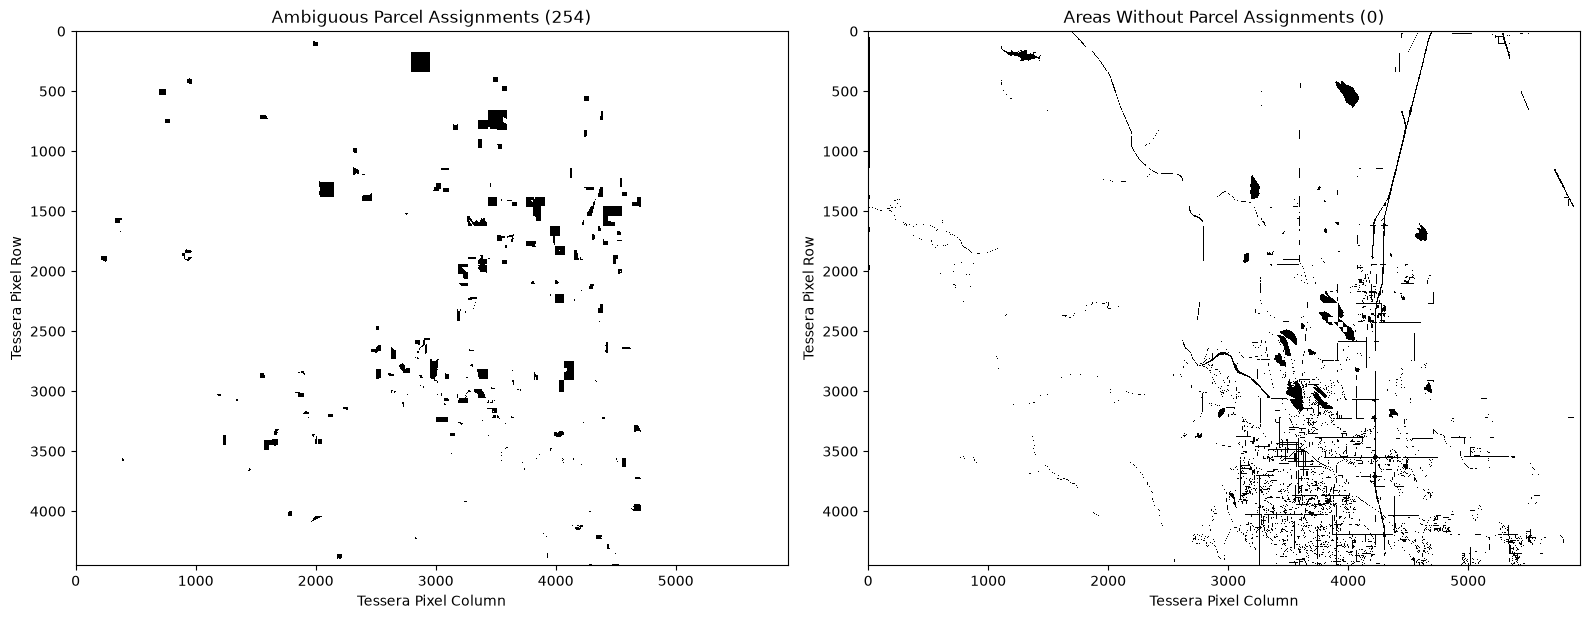

In [26]:

# Create separate diagnostic masks
ambiguous_mask = land_use_data == 254
no_parcel_mask = land_use_data == 0

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

axes[0].imshow(ambiguous_mask, cmap="gray_r", interpolation="nearest")
axes[0].set_title("Ambiguous Parcel Assignments (254)")

axes[1].imshow(no_parcel_mask, cmap="gray_r", interpolation="nearest")
axes[1].set_title("Areas Without Parcel Assignments (0)")

for ax in axes:
    ax.set_xlabel("Tessera Pixel Column")
    ax.set_ylabel("Tessera Pixel Row")

plt.tight_layout()

plt.savefig(
    "data/visualizations/land_use_quality_masks.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()


AI assistance was used for preprocessing strategy, code development, and debugging